# Исследование факторов ценообразования на рынке бриллиантов
Выполнил: Микуров Дмитрий Николаевич, группа 6401-020302D  
Дисциплина: Инструментальные средства анализа данных

## Цель и аналитические вопросы
Цель проекта — построить воспроизводимый end-to-end аналитический пайплайн от загрузки и очистки данных до статистического анализа, SQL-запросов, визуализации и содержательных выводов.

Аналитические вопросы:
1. Какие физические и качественные параметры бриллиантов (вес в каратах, огранка, цвет, чистота) сильнее всего связаны с ценой (`price`)?
2. Как меняется удельная стоимость одного карата (`price_per_carat`) при переходе между весовыми категориями и классами огранки?

## Этап 1. Загрузка данных и первичный обзор структуры

In [4]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("../data/raw_dataset.csv")

display(df.head())
print("Размерность датасета:", df.shape)
print("\nИнформация о типах и пропусках:")
df.info()
print("\nОписательная статистика числовых признаков:")
display(df.describe())
print("\nОписательная статистика категориальных признаков:")
display(df.describe(include="object"))

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Размерность датасета: (53940, 10)

Информация о типах и пропусках:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB

Описательная статистика числовых признаков:


,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000



Описательная статистика категориальных признаков:


,cut,color,clarity
count,53940,53940,53940
unique,5,7,8
top,Ideal,G,SI1
freq,21551,11292,13065


## Этап 2. Очистка данных, обработка аномалий и генерация новых признаков

In [5]:
print("Количество пропусков по столбцам:\n", df.isnull().sum())
duplicates_count = df.duplicated().sum()
print("Количество полных дубликатов:", duplicates_count)

df_clean = df.drop_duplicates().copy()

zero_dims = df_clean[(df_clean["x"] <= 0) | (df_clean["y"] <= 0) | (df_clean["z"] <= 0)]
print("Записей с нулевыми физическими габаритами (x, y или z = 0):", len(zero_dims))

df_clean = df_clean[(df_clean["x"] > 0) & (df_clean["y"] > 0) & (df_clean["z"] > 0)].copy()

cut_order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
df_clean["cut"] = pd.Categorical(df_clean["cut"], categories=cut_order, ordered=True)

df_clean["price_per_carat"] = df_clean["price"] / df_clean["carat"]
df_clean["volume_mm3"] = df_clean["x"] * df_clean["y"] * df_clean["z"]
df_clean["weight_category"] = pd.cut(
    df_clean["carat"],
    bins=[0, 0.5, 1.0, 1.5, 6.0],
    labels=["Мелкие (<=0.5 ct)", "Средние (0.5-1.0 ct)", "Крупные (1.0-1.5 ct)", "Экстра (>1.5 ct)"]
)

print("Размерность после очистки:", df_clean.shape)
display(df_clean[["carat", "cut", "price", "price_per_carat", "volume_mm3", "weight_category"]].head())

Количество пропусков по столбцам:
 carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64
Количество полных дубликатов: 146
Записей с нулевыми физическими габаритами (x, y или z = 0): 19
Размерность после очистки: (53775, 13)


,carat,cut,price,price_per_carat,volume_mm3,weight_category
0,0.23,Ideal,326,1417.391304,38.202030,Мелкие (<=0.5 ct)
1,0.21,Premium,326,1552.380952,34.505856,Мелкие (<=0.5 ct)
2,0.23,Good,327,1421.739130,38.076885,Мелкие (<=0.5 ct)
3,0.29,Premium,334,1151.724138,46.724580,Мелкие (<=0.5 ct)
4,0.31,Good,335,1080.645161,51.917250,Мелкие (<=0.5 ct)


## Этап 3. Анализ данных (Pandas и SQLite)

In [6]:
corr_matrix = df_clean[["carat", "depth", "table", "price", "price_per_carat", "volume_mm3"]].corr()
print("Корреляция признаков с ценой (price):")
display(corr_matrix["price"].sort_values(ascending=False).to_frame())

cut_summary = (df_clean
    .groupby("cut", observed=False)
    .agg(
        count=("price", "count"),
        mean_carat=("carat", "mean"),
        median_price=("price", "median"),
        mean_price_per_carat=("price_per_carat", "mean")
    )
    .reset_index())
display(cut_summary)

conn = sqlite3.connect(":memory:")
df_clean.to_sql("diamonds", conn, index=False, if_exists="replace")

sql_query = """
SELECT
    weight_category,
    cut,
    COUNT(*) AS items_count,
    ROUND(AVG(price), 2) AS avg_price,
    ROUND(AVG(price_per_carat), 2) AS avg_price_per_carat
FROM diamonds
GROUP BY weight_category, cut
ORDER BY weight_category, avg_price_per_carat DESC
"""
sql_result = pd.read_sql_query(sql_query, conn)
conn.close()

display(sql_result.head(15))

Корреляция признаков с ценой (price):


,price
price,1.000000
carat,0.921548
price_per_carat,0.912718
volume_mm3,0.904097
table,0.126666
depth,-0.011144


,cut,count,mean_carat,median_price,mean_price_per_carat
0,Fair,1597,1.043676,3282.0,3761.648366
1,Good,4888,0.846710,3038.0,3859.093893
2,Very Good,12068,0.806179,2646.5,4014.438677
3,Premium,13737,0.891072,3180.0,4222.510117
4,Ideal,21485,0.703394,1813.0,3922.376246


,weight_category,cut,items_count,avg_price,avg_price_per_carat
0,Крупные (1.0-1.5 ct),Ideal,4118,7057.79,6145.41
1,Крупные (1.0-1.5 ct),Very Good,2723,6502.68,5641.67
2,Крупные (1.0-1.5 ct),Premium,3715,6264.34,5380.87
3,Крупные (1.0-1.5 ct),Good,1089,5896.15,5109.70
4,Крупные (1.0-1.5 ct),Fair,383,4995.65,4257.07
5,Мелкие (<=0.5 ct),Ideal,9104,863.97,2429.97
6,Мелкие (<=0.5 ct),Fair,190,1017.76,2392.03
7,Мелкие (<=0.5 ct),Premium,4303,863.22,2372.09
8,Мелкие (<=0.5 ct),Very Good,3884,766.58,2164.65
9,Мелкие (<=0.5 ct),Good,1382,786.49,2078.83


## Этап 4. Визуализация результатов исследования

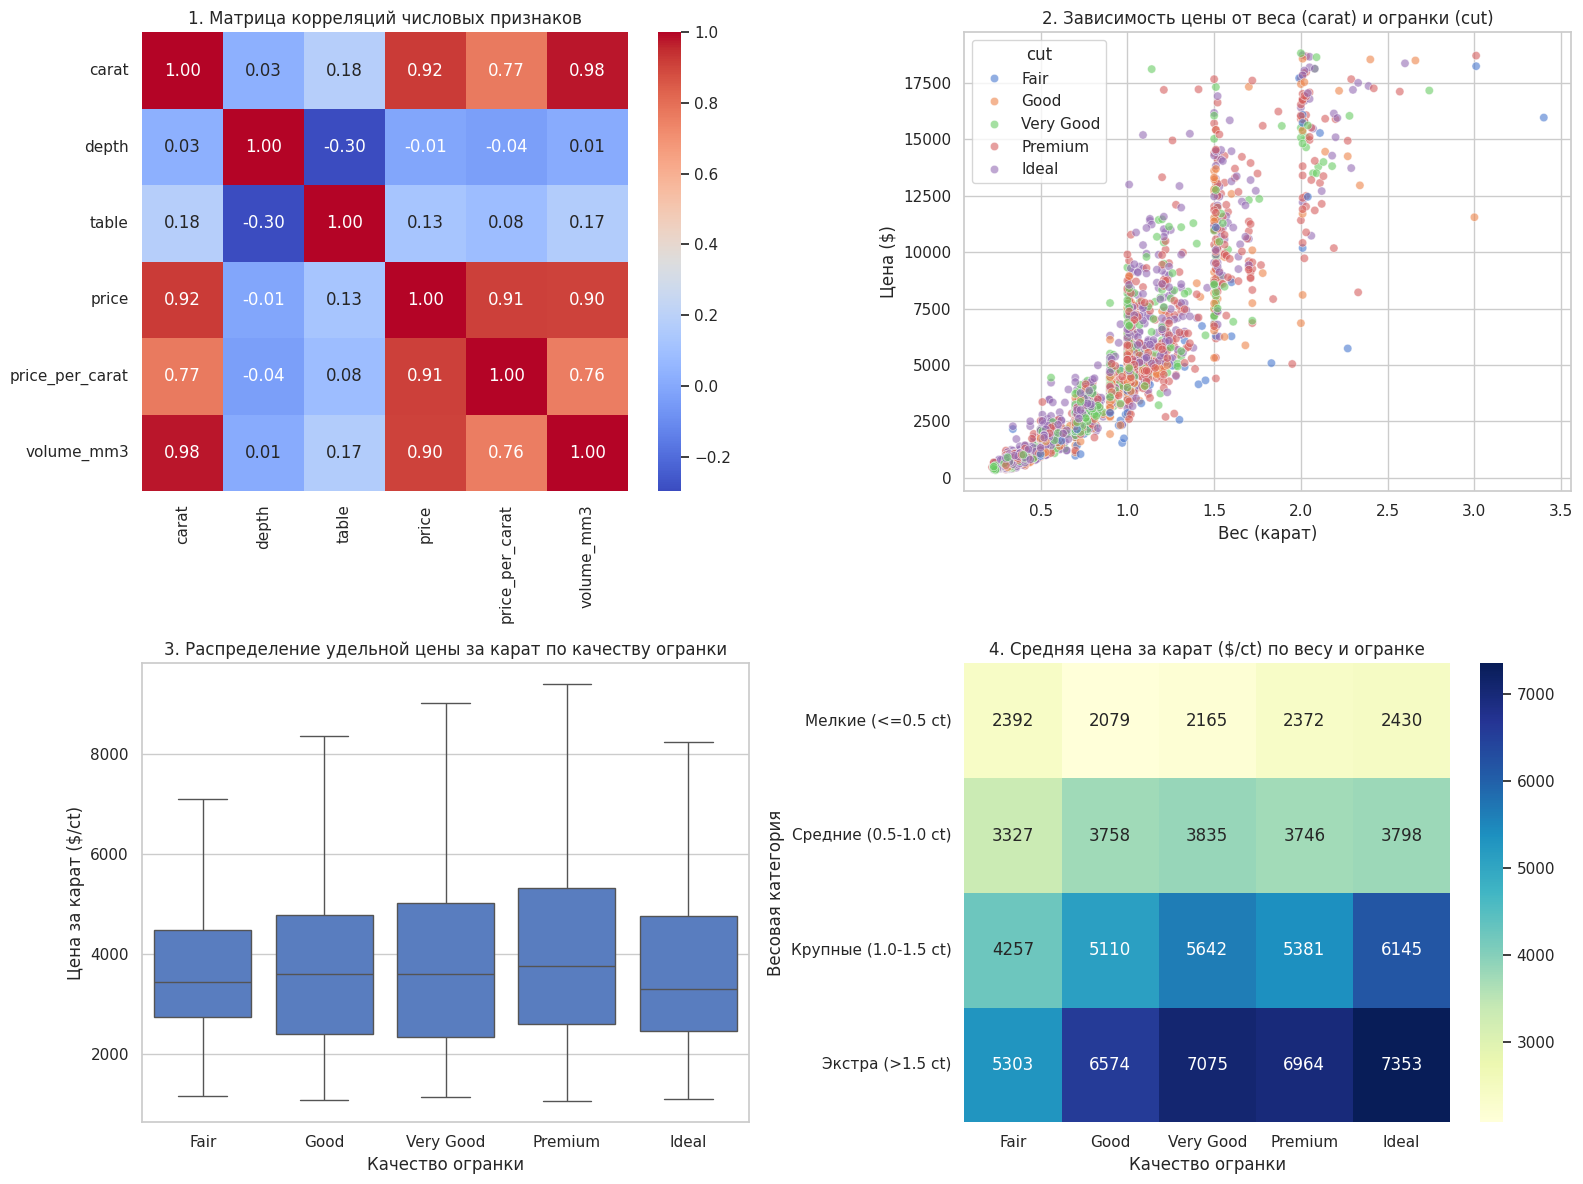

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0, 0])
axes[0, 0].set_title("1. Матрица корреляций числовых признаков")

sample_df = df_clean.sample(3000, random_state=42)
sns.scatterplot(
    data=sample_df, x="carat", y="price", hue="cut", alpha=0.6, ax=axes[0, 1]
)
axes[0, 1].set_title("2. Зависимость цены от веса (carat) и огранки (cut)")
axes[0, 1].set_xlabel("Вес (карат)")
axes[0, 1].set_ylabel("Цена ($)")

sns.boxplot(
    data=df_clean, x="cut", y="price_per_carat", showfliers=False, ax=axes[1, 0]
)
axes[1, 0].set_title("3. Распределение удельной цены за карат по качеству огранки")
axes[1, 0].set_xlabel("Качество огранки")
axes[1, 0].set_ylabel("Цена за карат ($/ct)")

pivot_heat = df_clean.pivot_table(
    values="price_per_carat", index="weight_category", columns="cut", aggfunc="mean", observed=False
)
sns.heatmap(pivot_heat, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1, 1])
axes[1, 1].set_title("4. Средняя цена за карат ($/ct) по весу и огранке")
axes[1, 1].set_xlabel("Качество огранки")
axes[1, 1].set_ylabel("Весовая категория")

plt.tight_layout()
plt.show()

## Этап 5. Итоговые выводы

1. Главный драйвер стоимости — физический размер и масса камня: согласно матрице корреляций (График 1) и диаграмме рассеяния (График 2), итоговая цена бриллианта (`price`) имеет сильнейшую положительную линейную связь с весом в каратах (`carat`, $r = 0.92$) и объёмом камня (`volume_mm3`, $r = 0.90$), причём зависимость носит выраженный нелинейный (степенной) характер.
2. Парадокс средней цены по классам огранки: первичная агрегация показывает, что камни с идеальной огранкой (`Ideal`) в среднем стоят дешевле камней с огранкой `Premium` или `Fair`. Это объясняется эффектом смещения выборки: среди камней `Ideal` преобладают мелкие бриллианты (средний вес 0.70 ct против 1.05 ct у `Fair`), тогда как крупные камни реже подвергаются идеальной огранке ради сохранения массы.
3. Рост удельной стоимости карата и влияние огранки внутри весовых групп: анализ удельной цены (`price_per_carat`) с помощью SQL-агрегации и сводной тепловой карты (График 4) подтверждает, что при переходе от мелких камней ($\le 0.5$ ct) к категории экстра ($> 1.5$ ct) стоимость одного карата возрастает более чем в 3 раза (с ~$2 400 до >$8 000 за карат). Внутри одной и той же весовой категории бриллианты с огранкой `Ideal` стабильно оцениваются выше камней с огранкой `Fair` и `Good` (График 3).

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
fatal: Unable to read current working directory: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
fatal: Unable to read current working directory: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
fatal: Unable to read current working directory: No such file or directory
